# Chapitre 9 - Cours 5 : le consensus en pratique, Raft

Le cours précédent a montré que le consensus équivaut à un **journal partagé**, et
qu'un journal tenu par un leader unique est facile... tant que le leader ne tombe pas.
Les algorithmes de consensus utilisés en pratique (Raft, Multi-Paxos, Zab,
Viewstamped Replication) sont essentiellement de la **réplication à leader unique avec
élection et bascule automatiques, sans cerveau divisé ni perte d'écriture validée**. Ce
notebook implémente **Raft** sur le simulateur (`cs.RaftNode`), l'observe sur des
diagrammes espace-temps, le soumet à des pannes et à des partitions, vérifie sa sûreté
et mesure ce qu'il coûte. Il couvre la fin de la section *Fault-Tolerant Consensus* : *Consensus algorithms and total order broadcast*, *Single-leader replication and consensus*, *Epoch numbering and quorums*, *Limitations of consensus*.

**Plan.**

1. De la réplication à leader unique au consensus.
2. Mandats et quorums qui se recoupent.
3. Raft sur le simulateur : l'élection.
4. Réplication du journal et validation par majorité.
5. Pannes et partitions : le leader isolé, les lectures linéarisables.
6. Le nouveau leader doit être à jour.
7. Avantages et limites du consensus.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
TERM_COLORS = [GRAY, INDIGO, TEAL, AMBER, VIOLET, SKY, ROSE, GREEN, SLATE]


def dessine_journaux(nodes, ax, titre, sous_titre=""):
    """Grille des journaux : une ligne par nœud, une case par entrée colorée par mandat ;
    trait vert = indice de validation connu du nœud, contour épais = leader."""
    names = list(nodes)
    width = max(len(n.log) for n in nodes.values())
    for i, x in enumerate(names):
        nd = nodes[x]
        y = len(names) - 1 - i
        for k, e in enumerate(nd.log[1:], start=1):
            c = TERM_COLORS[e.term % len(TERM_COLORS)]
            cmd = e.cmd
            lab = "·" if cmd[0] == "noop" else (f"x={cmd[2]}" if cmd[0] == "set" else
                                                 ("lect." if cmd[0] == "read" else f"cas→{cmd[3]}"))
            ax.add_patch(plt.Rectangle((k - 0.45, y - 0.35), 0.9, 0.7, facecolor=LIGHT.get(c, "#F1F5F9"),
                                       edgecolor=c, lw=1.4))
            ax.text(k, y + 0.08, lab, ha="center", va="center", fontsize=8, color=SLATE)
            ax.text(k, y - 0.22, f"m{e.term}", ha="center", va="center", fontsize=6.5, color=c)
        if nd.commit:
            ax.plot([nd.commit + 0.5] * 2, [y - 0.45, y + 0.45], color=GREEN, lw=2.5)
        state = "leader" if nd.role == "leader" else ("en panne" if not nd.up else nd.role.replace("follower", "suiveur").replace("candidate", "candidat"))
        ax.text(-0.2, y, f"{x} ({state}, m{nd.term})", ha="right", va="center", fontsize=8.5,
                color=ROSE if not nd.up else SLATE, fontweight="bold" if nd.role == "leader" else "normal")
    ax.set_xlim(-0.1, width + 0.2); ax.set_ylim(-0.6, len(names) - 0.4)
    ax.set_xticks(range(1, width)); ax.set_yticks([]); ax.grid(False)
    for s_ in ("left", "top", "right"):
        ax.spines[s_].set_visible(False)
    ax.set_xlabel("indice dans le journal")
    ax.set_title(titre)
    if sous_titre:
        subtitle(ax, sous_titre)


def zoom(st, t0, t1):
    """Restreint un diagramme espace-temps à [t0, t1] en gardant les noms des nœuds visibles."""
    st.ax.set_xlim(t0 - 0.02 * (t1 - t0), t1)
    for txt in st.ax.texts[:len(st.nodes)]:
        txt.set_x(t0 - 0.015 * (t1 - t0))


def leader_actuel(nodes):
    ls = [x for x, n in nodes.items() if n.role == "leader" and n.up]
    return max(ls, key=lambda x: nodes[x].term) if ls else None

## 1. De la réplication à leader unique au consensus (section *Single-leader replication and consensus*)

Un journal partagé est facile si **un seul** leader a le droit d'y ajouter des entrées. La
question est : que faire quand il tombe ? Les bases à leader unique traditionnelles ne
répondaient pas : la **bascule** était confiée à un administrateur. Outre l'indisponibilité
(un humain ne réagit pas en millisecondes), cela viole la **terminaison** du consensus.
Il faut donc que l'algorithme **élise lui-même** un nouveau leader.

Difficulté : pour éviter le **cerveau divisé** (deux nœuds qui se croient leaders et
prennent des décisions contradictoires), tous les nœuds doivent s'accorder sur l'identité
du leader. Il faudrait donc un consensus pour élire un leader... et un leader pour obtenir
un consensus. Comment sortir de ce cercle ?

> **À retenir.** Le consensus en pratique, c'est la réplication à leader unique **plus**
> une élection automatique sûre. Le défi est d'élire sans déjà disposer d'un consensus.

## 2. Mandats et quorums qui se recoupent (section *Epoch numbering and quorums*)

Les algorithmes de consensus ne garantissent **pas** qu'il n'y ait qu'un leader à chaque
instant. Ils garantissent plus faible : ils numérotent des **époques** (numéro de scrutin
chez Paxos, numéro de vue chez Viewstamped Replication, **mandat** ou *term* chez Raft) et
assurent qu'**au sein d'une époque, le leader est unique**.

- Un nœud qui n'entend plus le leader pendant un certain délai lance une élection avec un
  numéro d'époque **plus grand** que tous ceux qu'il connaît.
- En cas de conflit entre deux leaders d'époques différentes (l'ancien n'était pas mort,
  juste lent), celui de l'époque **la plus grande** l'emporte.
- Avant d'ajouter une entrée, le leader recueille les votes d'un **quorum** (en général
  une majorité) ; un nœud ne vote oui que s'il ne connaît pas de leader d'époque plus
  grande.

Il y a donc **deux votes** : un pour élire le leader, un pour chaque proposition. Les
quorums des deux votes **se recoupent** : au moins un nœud qui accepte une proposition a
participé à la dernière élection réussie. Si aucun nœud du quorum ne signale une époque
plus grande, le leader sait qu'aucune élection plus récente n'a abouti, et il peut
ajouter l'entrée sans danger.

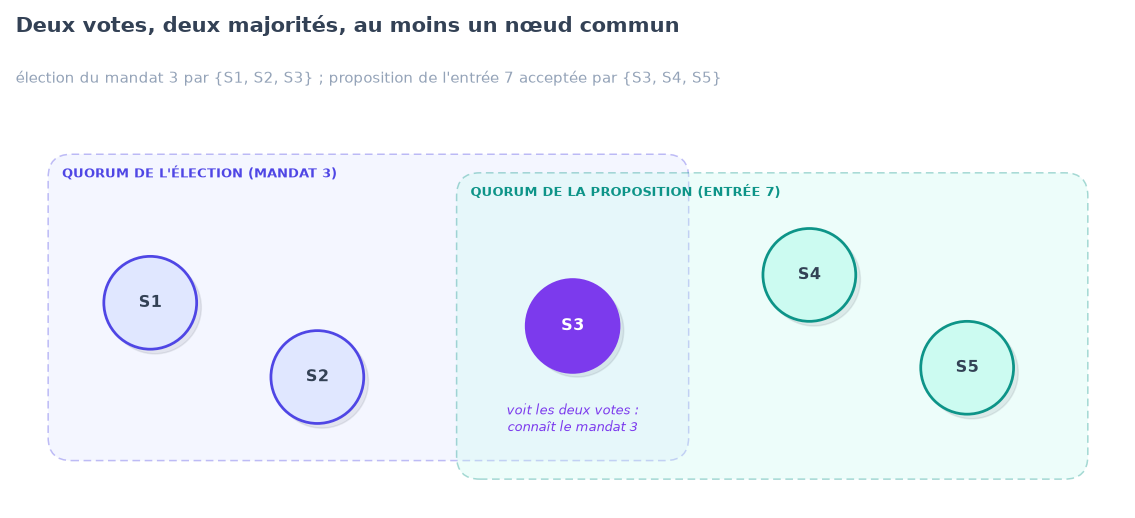

In [2]:
d = Diagram(12, 4.4, title="Deux votes, deux majorités, au moins un nœud commun",
            subtitle="élection du mandat 3 par {S1, S2, S3} ; proposition de l'entrée 7 acceptée par {S3, S4, S5}")
d.group(0.4, 0.5, 7.3, 3.8, "quorum de l'élection (mandat 3)", color=INDIGO)
d.group(4.8, 0.3, 11.6, 3.6, "quorum de la proposition (entrée 7)", color=TEAL)
for name, x, y, c in [("S1", 1.5, 2.2, INDIGO), ("S2", 3.3, 1.4, INDIGO), ("S3", 6.05, 1.95, VIOLET),
                      ("S4", 8.6, 2.5, TEAL), ("S5", 10.3, 1.5, TEAL)]:
    d.box(name, x, y, name, kind="circle", w=1.0, color=c, filled=name == "S3")
d.note(6.05, 0.95, "voit les deux votes :\nconnaît le mandat 3", color=VIOLET, fontsize=8.5)
d.show()

Ces deux tours de vote ressemblent superficiellement à la validation à deux phases
(cours 3), mais ce sont des protocoles très différents : dans un consensus,
**n'importe quel** nœud peut lancer une élection et il suffit d'un **quorum** de réponses ;
dans 2PC, seul le coordinateur sollicite des votes et il lui faut le **oui de tous** les
participants.

> **À retenir.** Un leader unique **par époque**, des époques croissantes, et des quorums
> d'élection et de proposition qui se recoupent : c'est la structure commune de Raft,
> Multi-Paxos, Zab et Viewstamped Replication.

## 3. Raft sur le simulateur : l'élection (section *Consensus algorithms and total order broadcast*)

Raft a été conçu pour être compréhensible. Chaque nœud est **suiveur**, **candidat** ou
**leader**, et conserve sur disque son mandat courant, son vote du mandat et son journal.

- Le leader envoie régulièrement des **battements** (`AppendEntries`, éventuellement
  vides). Un suiveur qui n'en reçoit pas pendant un **délai d'élection tiré au hasard**
  (ici entre 15 et 30 unités, contre 5 entre battements) devient candidat : il incrémente
  son mandat, vote pour lui et demande les votes des autres (`RequestVote`).
- Un nœud accorde **au plus un vote par mandat**, et seulement si le journal du candidat
  est **au moins aussi à jour** que le sien (section 6).
- Un candidat qui obtient une **majorité** devient leader ; un nœud qui voit un mandat plus
  grand que le sien redevient suiveur.

Le hasard des délais (cf. FLP, cours précédent) fait qu'en général un seul nœud se
réveille en premier et gagne avant que les autres ne se présentent. Observons la
première élection d'une grappe de cinq nœuds.

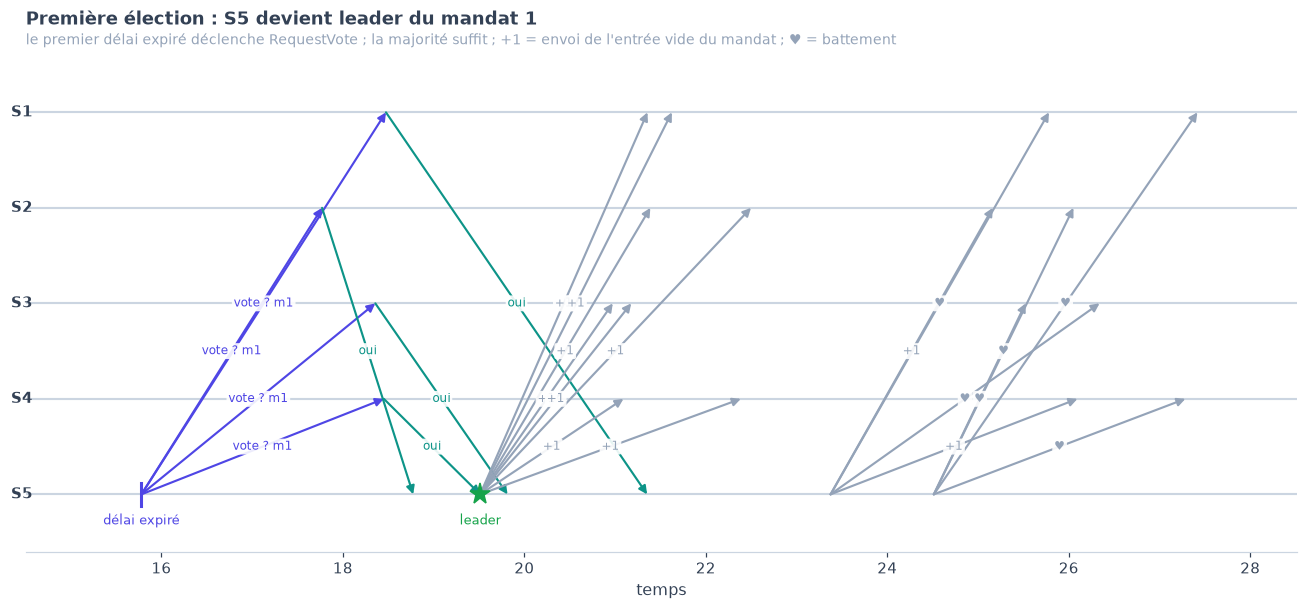

In [3]:
net, nodes, trace = cs.raft_cluster(5, seed=1, latency=(1.0, 3.0))
net.run(until=40)
t_el = cs.raft_leaders(trace)[0][0]
cand = [e for e in trace if e["kind"] == "candidate"][0]
col = {"RequestVote": INDIGO, "Vote": TEAL, "Append": GRAY, "AppendResp": GRAY}
def etiquette(d):
    m = d.msg
    if m[0] == "RequestVote":
        return f"vote ? m{m[1]}"
    if m[0] == "Vote":
        return "oui" if m[2] else "non"
    if m[0] == "Append":
        return "♥" if not m[5] else f"+{len(m[5])}"
    return ""
t0, t1 = cand["t"] - 1, t_el + 9
st = SpaceTime(list(nodes), t_max=t1, width=12, title=f"Première élection : {cand['node']} devient leader du mandat 1",
               subtitle="le premier délai expiré déclenche RequestVote ; la majorité suffit ; +1 = envoi de l'entrée vide du mandat ; ♥ = battement")
zoom(st, t0, t1)
st.from_trace([d for d in net.trace if t0 <= d.t_send <= t1 and d.msg[0] != "AppendResp"],
              color_of=lambda d: col[d.msg[0]], label_of=etiquette)
st.event(cand["node"], cand["t"], "délai expiré", kind="tick", color=INDIGO)
st.event(cand["node"], t_el, "leader", kind="star", color=GREEN)
st.show()

Le nœud dont le délai expire le premier demande les votes avec le mandat 1 ; les autres,
qui n'ont voté pour personne dans ce mandat, acceptent. Dès la 3e voix (la sienne
comprise), il est leader et envoie des battements qui réarment le délai des suiveurs.
Que se passe-t-il quand le leader meurt ? Tuons-le plusieurs fois et traçons la frise
des mandats.

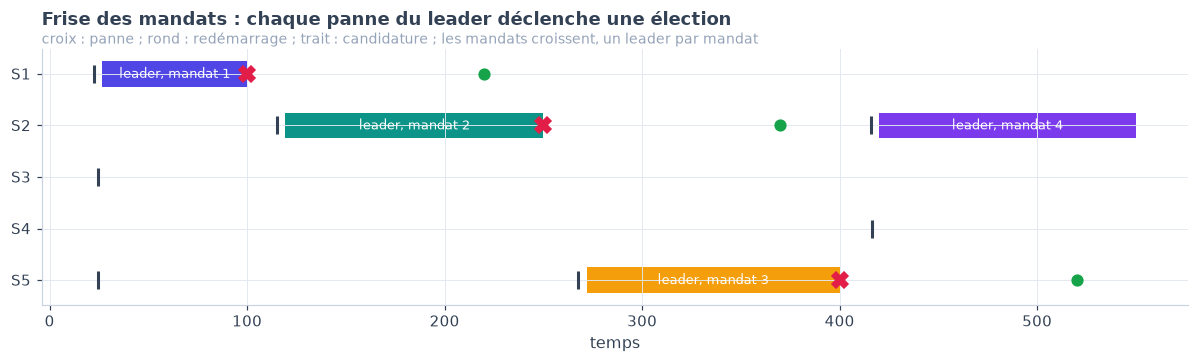

durées sans leader après chaque panne : [19.4, 21.9, 19.9]


In [4]:
net, nodes, trace = cs.raft_cluster(5, seed=3)
def tue_leader():
    x = leader_actuel(nodes)
    if x:
        net.crash(x)
        net.at(net.now + 120, net.recover, x)
for t in (100, 250, 400):
    net.at(t, tue_leader)
net.run(until=550)
fig, ax = plt.subplots(figsize=(11, 3.4))
names = list(nodes)
leaders = cs.raft_leaders(trace)
ends = [t for t, *_ in leaders[1:]] + [550]
for (t, x, term), te in zip(leaders, ends):
    crash = [e["t"] for e in trace if e["kind"] == "crash" and e["node"] == x and e["t"] > t]
    stop = min([te] + crash)
    c = TERM_COLORS[term % len(TERM_COLORS)]
    ax.barh(names.index(x), stop - t, left=t, color=c, height=0.5)
    ax.text((t + stop) / 2, names.index(x), f"leader, mandat {term}", ha="center", va="center", fontsize=8.5, color="white")
for e in trace:
    if e["kind"] == "crash":
        ax.plot(e["t"], names.index(e["node"]), "X", color=ROSE, ms=11)
    if e["kind"] == "recover":
        ax.plot(e["t"], names.index(e["node"]), "o", color=GREEN, ms=7)
    if e["kind"] == "candidate":
        ax.plot(e["t"], names.index(e["node"]), "|", color=SLATE, ms=12, mew=2)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_xlabel("temps")
ax.set_title("Frise des mandats : chaque panne du leader déclenche une élection")
subtitle(ax, "croix : panne ; rond : redémarrage ; trait : candidature ; les mandats croissent, un leader par mandat")
plt.tight_layout(); plt.show()
indispo = []
for e in trace:
    if e["kind"] == "crash":
        nxt = [t for t, *_ in leaders if t > e["t"]]
        indispo.append(nxt[0] - e["t"])
print("durées sans leader après chaque panne :", [round(x, 1) for x in indispo])

Après chaque panne, il faut attendre l'expiration d'un délai d'élection (15 à 30 unités),
plus un aller-retour de votes : la grappe reste sans leader quelques dizaines d'unités.
Les nœuds redémarrés redeviennent de simples suiveurs du mandat courant.

> **À retenir.** Raft élit un leader par délais aléatoires et votes majoritaires, au plus
> un vote par nœud et par mandat. Une panne du leader coûte environ un délai d'élection
> d'indisponibilité.

## 4. Réplication du journal et validation par majorité

Le leader ajoute chaque commande d'un client à son journal, puis l'envoie aux suiveurs
(`AppendEntries`, avec l'indice et le mandat de l'entrée **précédente** : un suiveur dont
le journal ne concorde pas à cet endroit refuse, et le leader recule jusqu'au point
d'accord, puis écrase la suite divergente). Une entrée est **validée** (committed) dès
qu'elle est stockée sur une **majorité** ; le leader l'applique alors à sa machine à états
(ici un dictionnaire clé-valeur), répond au client et communique le nouvel indice de
validation aux suiveurs, qui l'appliquent à leur tour. C'est la seconde majorité de la
section 2 : une entrée confirmée au client survit à la panne du leader.

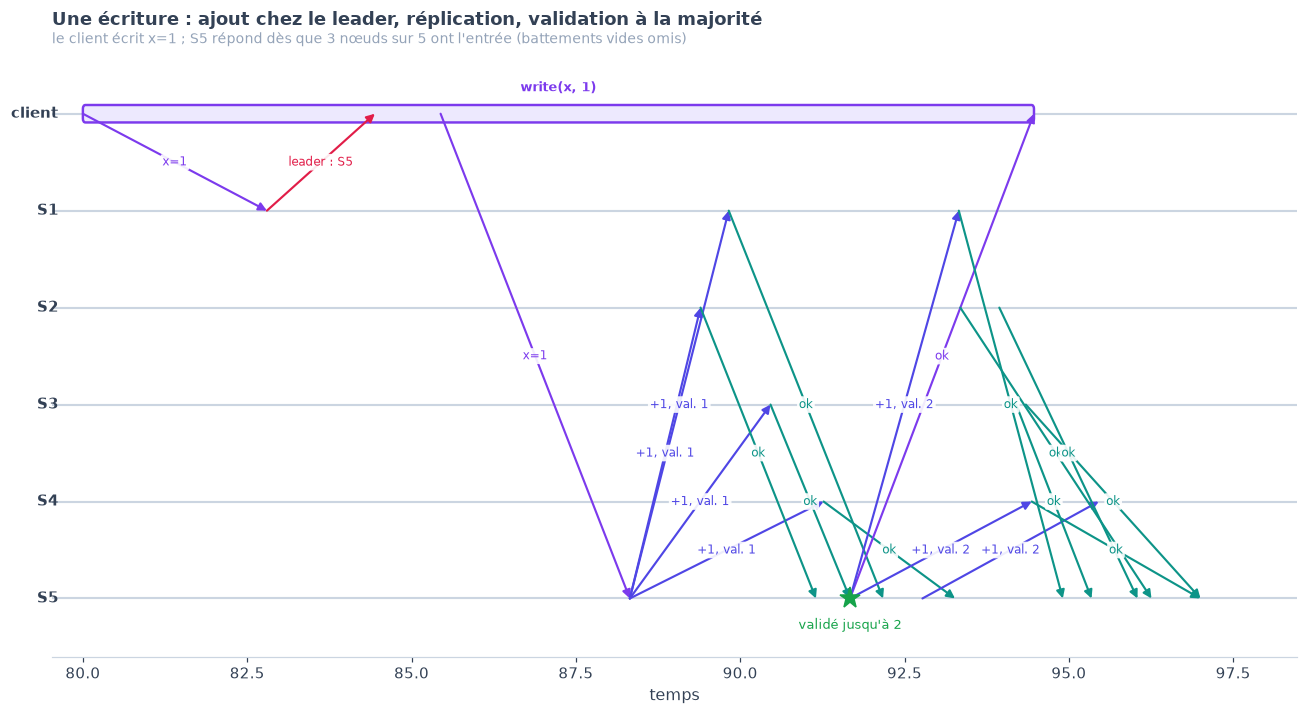

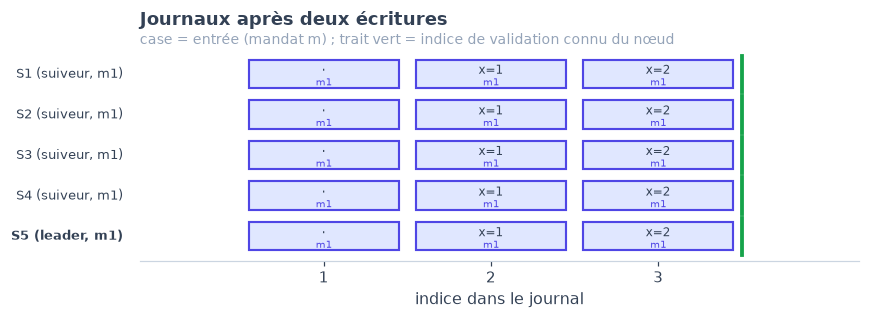

In [5]:
net, nodes, trace = cs.raft_cluster(5, seed=1, latency=(1.0, 3.0), heartbeat=12.0, election_timeout=(40.0, 60.0))
hist = []
net.add(cs.RaftClient("client", list(nodes), [(80, "write", 1), (30, "write", 2)], history=hist))
net.run(until=79.9)
t0 = net.now
net.run(until=105)
op = hist[0]
L = leader_actuel(nodes)
col = {"Submit": VIOLET, "Reply": VIOLET, "NotLeader": ROSE, "Append": INDIGO, "AppendResp": TEAL}
def etiq(d):
    m = d.msg
    if m[0] == "Submit":
        return f"x={m[2][2]}"
    if m[0] == "Reply":
        return "ok"
    if m[0] == "NotLeader":
        return f"leader : {m[2]}"
    if m[0] == "Append":
        return "♥" if not m[5] else f"+{len(m[5])}, val. {m[6]}"
    return "ok" if m[2] else "refus"
st = SpaceTime(["client"] + list(nodes), t_max=op.t_return + 4, width=12,
               title="Une écriture : ajout chez le leader, réplication, validation à la majorité",
               subtitle=f"le client écrit x=1 ; {L} répond dès que 3 nœuds sur 5 ont l'entrée (battements vides omis)")
zoom(st, t0, op.t_return + 4)
t_rep = min(d.t_send for d in net.trace if d.t_send >= t0 and d.msg[0] == "Append" and d.msg[5])
st.from_trace([d for d in net.trace if t0 <= d.t_send <= op.t_return and not (d.msg[0] == "Append" and not d.msg[5])
               and not (d.msg[0] == "AppendResp" and d.t_send < t_rep)], color_of=lambda d: col.get(d.msg[0], GRAY),
              label_of=etiq)
st.op("client", op.t_call, op.t_return, "write(x, 1)", color=VIOLET)
for e in trace:
    if e["kind"] == "commit" and t0 <= e["t"] <= op.t_return:
        st.event(e["node"], e["t"], f"validé jusqu'à {e['index']}", kind="star", color=GREEN)
st.show()
fig, ax = plt.subplots(figsize=(8, 3))
net.run(until=200)
dessine_journaux(nodes, ax, "Journaux après deux écritures", "case = entrée (mandat m) ; trait vert = indice de validation connu du nœud")
plt.tight_layout(); plt.show()

Le client a d'abord contacté un nœud qui n'était pas leader (s'il y a lieu, réponse « leader :
… ») puis le leader, qui a validé dès les trois premiers accusés de réception. La
première entrée de chaque journal est l'entrée vide (« · ») qu'un nouveau leader ajoute en
début de mandat pour faire valider sans attendre les entrées des mandats précédents.

> **À retenir.** Une entrée est validée quand une majorité la stocke ; le leader ne répond
> qu'à ce moment. La vérification de l'entrée précédente garantit que deux journaux qui
> concordent à un indice concordent sur tout ce qui précède.